# **EXERCICE 1 :**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

# Chargement des donnees
spam = pd.read_csv("/content/drive/MyDrive/Machine Learning/Cours 3/spam.csv", sep=";", decimal=",")
print(spam.head())

   make  address   all  num3d   our  over  remove  internet  order  mail  ...  \
0  0.00     0.64  0.64    0.0  0.32  0.00    0.00      0.00   0.00  0.00  ...   
1  0.21     0.28  0.50    0.0  0.14  0.28    0.21      0.07   0.00  0.94  ...   
2  0.06     0.00  0.71    0.0  1.23  0.19    0.19      0.12   0.64  0.25  ...   
3  0.00     0.00  0.00    0.0  0.63  0.00    0.31      0.63   0.31  0.63  ...   
4  0.00     0.00  0.00    0.0  0.63  0.00    0.31      0.63   0.31  0.63  ...   

   charSemicolon  charRoundbracket  charSquarebracket  charExclamation  \
0           0.00             0.000                0.0            0.778   
1           0.00             0.132                0.0            0.372   
2           0.01             0.143                0.0            0.276   
3           0.00             0.137                0.0            0.137   
4           0.00             0.135                0.0            0.135   

   charDollar  charHash  capitalAve  capitalLong  capitalTotal  type

In [ ]:
X = spam.drop("type", axis=1) #type est la colonne qui dit "spam" ou "nonspam"
y = spam["type"]

1. En R, la fonction plot(rf1) affiche l’erreur OOB (Out-Of-Bag) en fonction du nombre d’arbres.
En Python, nous pouvons reconstruire ce comportement en utilisant l’argument warm_start=True.
Analyser et expliquer le graphe généré par le code suivant :

/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too fe

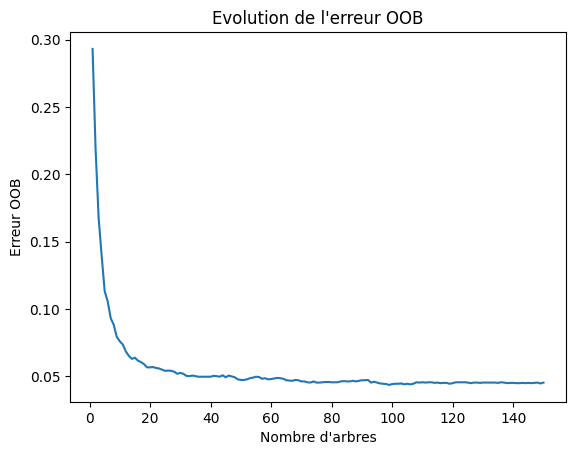

In [ ]:
rf1 = RandomForestClassifier(oob_score=True , warm_start=True , random_state =42)
erreurs_oob = []

for i in range(1, 151):
  rf1.set_params(n_estimators=i)
  rf1.fit(X, y)
  # L'erreur OOB est 1 - le score OOB
  erreurs_oob.append (1 - rf1.oob_score_)

plt.plot(range(1, 151), erreurs_oob)
plt.xlabel("Nombre d'arbres")
plt.ylabel("Erreur OOB")
plt.title("Evolution de l'erreur OOB")
plt.show()

En fixant warm_start=True, Scikit-Learn conserve les arbres déjà entraînés et se contente d'en ajouter de nouveaux à chaque itération du for. Cela permet d'évaluer le score Out-Of-Bag (OOB) pour $N = 1, 2, \dots, 150$ arbres sans ré-entraîner toute la forêt depuis le début à chaque boucle.   

Ce qu'est l'erreur OOB :

Le score OOB représente la précision du modèle évaluée sur les exemples Out-Of-Bag (les données non tirées lors du bootstrap pour un arbre donné). L'erreur OOB vaut donc $1 - \text{oob\_score\_}$.   

Analyse de la courbe obtenue :
- Au démarrage ($N$ très petit, 1 à 10 arbres) : L'erreur OOB est très haute et instable. Avec peu d'arbres, le vote de la forêt n'est pas encore lissé.

- Phase de décroissance rapide (10 à 40 arbres) : L'ajout d'arbres réduit drastiquement la variance globale du modèle (effet d'agrégation / bagging).

- Stabilisation / Plateau (au-delà de 50–80 arbres) : L'erreur converge vers un asymptote. Ajouter plus d'arbres n'améliore plus significativement la performance (mais n'entraîne pas non plus d'surapprentissage).

2. Construire une nouvelle forêt aléatoire avec le paramètre max_features=1 (équivalent de mtry=1
en R) et comparer les erreurs OOB des 2 forêts.

/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too fe

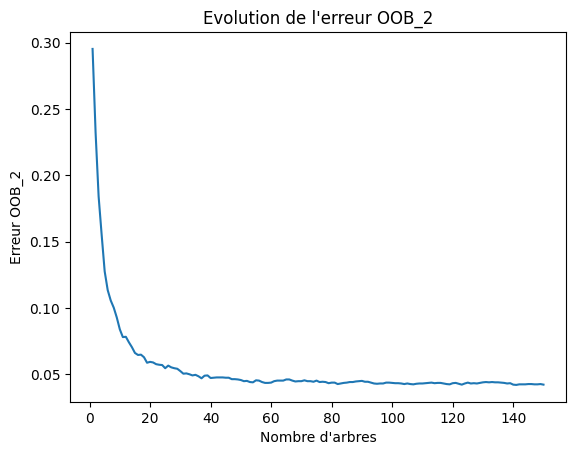

In [ ]:
rf2 = RandomForestClassifier(oob_score=True , warm_start=True ,max_features = 1, random_state =42)
erreurs_oob_2 = []

for i in range(1, 151):
  rf2.set_params(n_estimators=i)
  rf2.fit(X, y)
  # L'erreur OOB est 1 - le score OOB
  erreurs_oob_2.append (1 - rf2.oob_score_)

plt.plot(range(1, 151), erreurs_oob_2)
plt.xlabel("Nombre d'arbres")
plt.ylabel("Erreur OOB_2")
plt.title("Evolution de l'erreur OOB_2")
plt.show()

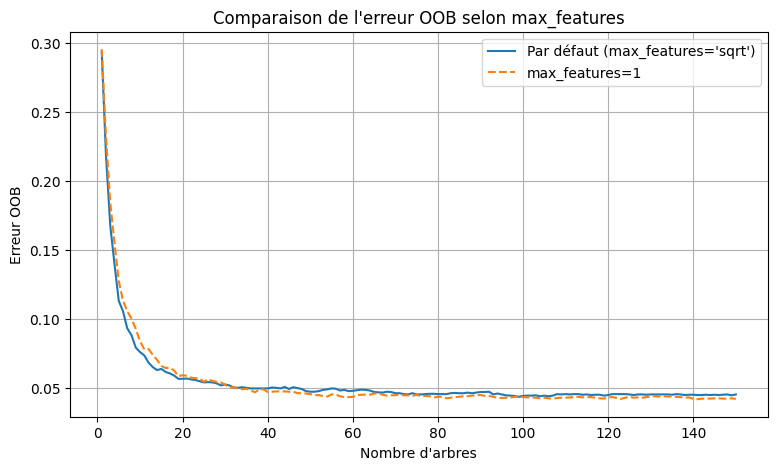

Erreur OOB finale (par défaut) : 0.0454
Erreur OOB finale (max_features=1) : 0.0422


In [ ]:
#COMPARAISON:

# Comparaison visuelle sur un même graphique
plt.figure(figsize=(9, 5))
plt.plot(range(1, 151), erreurs_oob, label="Par défaut (max_features='sqrt')")
plt.plot(range(1, 151), erreurs_oob_2, label="max_features=1", linestyle="--")
plt.xlabel("Nombre d'arbres")
plt.ylabel("Erreur OOB")
plt.title("Comparaison de l'erreur OOB selon max_features")
plt.legend()
plt.grid(True)
plt.show()

# Comparaison chiffrée
err_final_defaut = erreurs_oob[-1]
err_final_m1 = erreurs_oob_2[-1]

print(f"Erreur OOB finale (par défaut) : {err_final_defaut:.4f}")
print(f"Erreur OOB finale (max_features=1) : {err_final_m1:.4f}")

C'est une excellente observation. En théorie, diminuer max_features à $1$ rend chaque arbre individuel plus faible, mais cela produit souvent un meilleur résultat global sur certains jeux de données :

La décorrélation des arbres (effet Bagging) : L'erreur globale d'une forêt dépend de deux facteurs : la précision des arbres et la corrélation entre eux. Si un petit nombre de variables dans SpamBase sont ultra-dominantes (très prédictives), elles seront choisies à la racine de presque tous les arbres quand max_features est grand (sqrt). Les arbres se ressemblent alors beaucoup. En fixant max_features = 1, on force la forêt à explorer toutes les autres variables secondaires. Les arbres deviennent très différents les uns des autres (très décorrélés), ce qui fait drastiquement chuter la variance globale lors du vote final.

3. Séparer les données en un échantillon d’apprentissage de taille 3000 et un échantillon test de
taille 1601 (utiliser train_test_split du module sklearn.model_selection).

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size = 3000, test_size = 1601, random_state =42)

# Vérification des dimensions
print(f"Taille de X_train : {X_train.shape}")
print(f"Taille de X_test  : {X_test.shape}")

Taille de X_train : (3000, 57)
Taille de X_test  : (1601, 57)


4. Construire deux forêts aléatoires sur les données d’apprentissage : une avec les valeurs par défaut
(max_features="sqrt"), l’autre avec max_features=1.

In [ ]:
#Forêt 1 demandée : rf3
rf3 = RandomForestClassifier(oob_score=True , warm_start=True ,max_features = "sqrt", random_state =42)

#Forêt 2 demandée : rf4
rf4 = RandomForestClassifier(oob_score=True , warm_start=True ,max_features = 1, random_state =42)

#ENTRAINEMENT SUR LES DONNEES SEPAREES:

# Entraînement sur X_train et y_train
rf3.fit(X_train, y_train)
rf4.fit(X_train, y_train)

RandomForestClassifier(max_features=1, oob_score=True, random_state=42,
                       warm_start=True)

5. Calculer les erreurs de classification des deux forêts en utilisant les données test (via accuracy_score
ou en calculant 1 - rf.score(X_test, y_test)).

In [ ]:
from sklearn.metrics import accuracy_score

'''
# OPTION 1: Utiliser .score() directement
acc = rf_default.score(X_test, y_test)


# OPTION 2 : Utiliser predict + accuracy_score
y_pred = rf_default.predict(X_test)
acc = accuracy_score(y_test, y_pred)

# --> L'erreur de classification est simplement le complément :
erreur = 1 - acc
'''


#Calculer l'erreur de classification:

erreur_rf3_defaut = 1 - (rf3.score(X_test, y_test))
erreur_rf4_feature1 = 1 - (rf4.score(X_test, y_test))

print(erreur_rf3_defaut)
print(erreur_rf4_feature1)

0.044347282948157374
0.03747657713928798


6. Utiliser la classe GridSearchCV (équivalent de la fonction train du package caret) pour choisir
le paramètre max_features dans la grille allant de 1 à 30 par pas de 5 : range(1, 31, 5).

In [ ]:
from sklearn.model_selection import GridSearchCV #Cross-Validation

param_grid = {'max_features': list(range(1, 31, 5))} #ATTENTION AUX ESPACES DANS LES NOMS A RECUP DANS LES DATASET!!!!
grid = GridSearchCV(RandomForestClassifier(random_state =42), param_grid , cv=5)
grid.fit(X_train , y_train)
print("Meilleur parametre :", grid.best_params_) #best_params_ est une variable qui est obtenue lors de la CV grâce à GridSearch

Meilleur parametre : {'max_features': 1}


7. Construire un arbre de décision simple (DecisionTreeClassifier) sur les données d’apprentissage.

On construit un arbre de décision simple (DecisionTreeClassifier) sur les mêmes données d'apprentissage X_train et y_train pour pouvoir comparer plus tard ses performances avec les forêts aléatoires.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

arbre_decision = DecisionTreeClassifier(random_state=42)
arbre_decision.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

8. Comparer les courbes ROC et les AUC des 2 forêts (par défaut et optimisée) et de l’arbre. (On
utilisera l’échantillon test pour calculer les valeurs de probabilités via la méthode predict_proba
et les fonctions RocCurveDisplay ou roc_curve, auc de sklearn.metrics).

Note à moi-même :  là on reparle bien des deux forêts (rf3 et rf4) que j'ai fait tout à l'heure & de l'arbre de décision que je viens d'écrire.

- Probabilités de prédiction (predict_proba) : Contrairement à .predict() qui renvoie la classe finale (0 ou 1), .predict_proba() renvoie la probabilité qu'un individu appartienne à chaque classe. La colonne [:, 1] correspond à la probabilité d'être un spam.   

- La courbe ROC (Receiver Operating Characteristic) : Elle trace le taux de vrais positifs en fonction du taux de faux positifs pour tous les seuils de décision possibles.

- L'AUC (Area Under the Curve) :Elle mesure la capacité globale du modèle à séparer les spams des non-spams.Un score de 1,0 indique une séparation parfaite.Un score de 0,5 correspond à un modèle aléatoire (pile ou face).

- Ce qu'on attend visuellement :Les forêts aléatoires doivent obtenir une AUC très proche de 0,98 - 0,99, avec une courbe qui s'élève très vite vers le coin supérieur gauche.L'arbre de décision simple aura une AUC nettement inférieure (autour de 0,91 - 0,93), car un seul arbre surapprend sur le train et lisse beaucoup moins bien ses probabilités.

Note:

Quand tu appelles .predict_proba(X_test), Scikit-Learn ne te renvoie pas une simple liste de réponses (spam ou nonspam), mais un tableau 2D (une matrice) avec deux colonnes :

- Colonne 0 ([:, 0]) : La probabilité que l'email soit un nonspam (classe 0).
- Colonne 1 ([:, 1]) : La probabilité que l'email soit un spam (classe 1).

Pourquoi l'indice 1 correspond au spam ?

Dans Scikit-Learn, les classes sont automatiquement triées par ordre alphabétique (ou numérique) :
- "nonspam" arrive en premier $\rightarrow$ Indice 0
- "spam" arrive en second $\rightarrow$ Indice 1

Pour chaque ligne (chaque email de ton jeu de test), la somme des deux colonnes fait toujours $100\%$ ($1,0$).

Par exemple :Ligne 1 : [0.10, 0.90] $\rightarrow$ $10\%$ de chance d'être un nonspam, $90\%$ de chance d'être un spam.

Ligne 2 : [0.85, 0.15] $\rightarrow$ $85\%$ de chance d'être un nonspam, $15\%$ de chance d'être un spam.

Pourquoi la courbe ROC a besoin de ça ?

Pour tracer la courbe ROC, l'algorithme a besoin de faire varier le seuil de décision (par exemple : déclarer spam à partir de $20\%$, puis $30\%$, puis $50\%$, etc.) et de voir comment évoluent les faux positifs et vrais positifs. On lui donne donc la liste complète des probabilités d'être un spam, c'est-à-dire l'ensemble des lignes de la seconde colonne : [:, 1].

(En syntaxe Python/NumPy, : signifie « toutes les lignes » et 1 signifie « la deuxième colonne »).

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, roc_auc_score

# 1. Calcul des probabilités pour la classe positive ('spam')
# /!\ Si y contient des chaînes de caractères ('spam', 'nonspam'), la classe 1 est 'spam'
y_prob_rf_def = rf3.predict_proba(X_test)[:, 1] #celui par défaut c'est rf3 avec max_features="sqrt"
y_prob_rf_opt = grid.best_estimator_.predict_proba(X_test)[:, 1] #celui optimisé c'est rf4 avec max_features=1
y_prob_dt = arbre_decision.predict_proba(X_test)[:, 1]

'''
Pourquoi grid.best_estimator_ et pas une variable rf_opt ?
Quand on exécute grid.fit(X_train, y_train), Scikit-Learn fait deux choses :
- Il teste toutes les valeurs de max_features en validation croisée.
- Une fois le meilleur paramètre trouvé, il ré-entraîne automatiquement un modèle final
  sur la totalité de X_train avec ce paramètre optimal.
  Ce modèle final optimal est stocké directement à l'intérieur de
  l'objet grid, sous l'attribut grid.best_estimator_.
--> grid.best_estimator_ est le modèle rf_opt
'''

# 2. Calcul des scores AUC
auc_rf_def = roc_auc_score(y_test, y_prob_rf_def)
auc_rf_opt = roc_auc_score(y_test, y_prob_rf_opt)
auc_dt = roc_auc_score(y_test, y_prob_dt)

'''
La fonction prend deux arguments obligatoires :
- y_test : Les vraies étiquettes (la réalité : spam ou nonspam).
- y_prob : Les probabilités prédites par le modèle d'être un spam (la colonne [:, 1]).
Elle compare ces probabilités avec la réalité pour mesurer la qualité du classement du modèle.
'''

"\nLa fonction prend deux arguments obligatoires :\n- y_test : Les vraies étiquettes (la réalité : spam ou nonspam).\n- y_prob : Les probabilités prédites par le modèle d'être un spam (la colonne [:, 1]).\nElle compare ces probabilités avec la réalité pour mesurer la qualité du classement du modèle.\n"

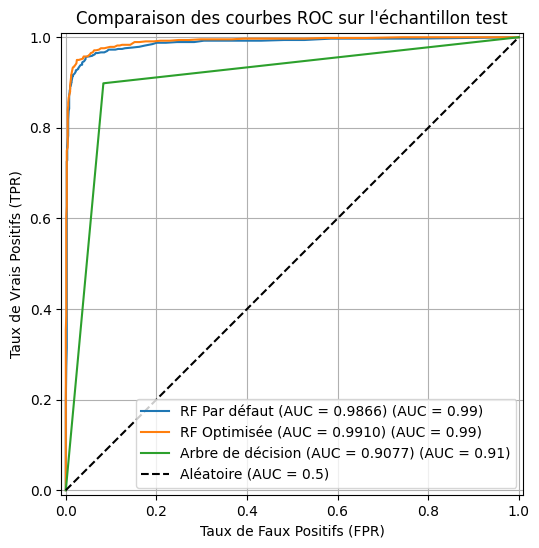

AUC - RF par défaut   : 0.9866
AUC - RF optimisée   : 0.9910
AUC - Arbre seul     : 0.9077


In [ ]:
# 3. Tracé des courbes ROC
plt.figure(figsize=(9, 6))

'''
MARCHE AUSSI AVEC ESTIMATOR:
RocCurveDisplay.from_estimator(
    rf_default, #modèle
    X_test, #entrée
    y_test, #sortie
    ax=plt.gca(),
    name=f"RF Par défaut (AUC = {auc_rf_def:.4f})", #--> il affiche tout seul les calculs fait avant
)
'''

RocCurveDisplay.from_predictions(
    y_test, #Les vraies classes de tes données de test ('spam' ou 'nonspam').
    y_prob_rf_def, #Le vecteur des probabilités d'être un spam, calculé à l'étape 1 via rf_default.predict_proba(X_test)[:, 1]
    pos_label="spam",  # Précise la classe positive
    ax=plt.gca(), #indique de dessiner sur le graphique courant, c'est pour que les 3 courbes soient sur le même graph
    name=f"RF Par défaut (AUC = {auc_rf_def:.4f})", #Le texte exact qui apparaîtra dans la légende.
)
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_rf_opt,
    pos_label="spam",  # Précise la classe positive
    ax=plt.gca(),
    name=f"RF Optimisée (AUC = {auc_rf_opt:.4f})",
)
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_dt,
    pos_label="spam",  # Précise la classe positive
    ax=plt.gca(),
    name=f"Arbre de décision (AUC = {auc_dt:.4f})",
)

plt.plot([0, 1], [0, 1], "k--", label="Aléatoire (AUC = 0.5)")#k=noir et - - = pointillé & [x_depart, x_arrivée], [y_depart, y_arrivee]
plt.title("Comparaison des courbes ROC sur l'échantillon test")
plt.xlabel("Taux de Faux Positifs (FPR)")
plt.ylabel("Taux de Vrais Positifs (TPR)")
plt.legend()
plt.grid(True)
plt.show()

# Print résumé
print(f"AUC - RF par défaut   : {auc_rf_def:.4f}")
print(f"AUC - RF optimisée   : {auc_rf_opt:.4f}")
print(f"AUC - Arbre seul     : {auc_dt:.4f}")

On voit que l'AUC est la meilleure avec la forêt optimisée (le plus proche de 1)

9. Calculer les erreurs de classification des 3 méthodes sur l’échantillon de test.

In [ ]:
# 9. Calcul et comparaison des erreurs de classification sur l'échantillon test
err_rf_def = 1 - rf3.score(X_test, y_test)
err_rf_opt = 1 - grid.best_estimator_.score(X_test, y_test)
err_dt = 1 - arbre_decision.score(X_test, y_test)

print("--- Erreurs de classification sur l'échantillon test ---")
print(f"RF Par défaut (max_features='sqrt') : {err_rf_def:.4f} (soit {err_rf_def*100:.2f} %)")
print(f"RF Optimisée (GridSearchCV)         : {err_rf_opt:.4f} (soit {err_rf_opt*100:.2f} %)")
print(f"Arbre de décision simple            : {err_dt:.4f} (soit {err_dt*100:.2f} %)")

--- Erreurs de classification sur l'échantillon test ---
RF Par défaut (max_features='sqrt') : 0.0443 (soit 4.43 %)
RF Optimisée (GridSearchCV)         : 0.0375 (soit 3.75 %)
Arbre de décision simple            : 0.0912 (soit 9.12 %)


10. Représenter les 10 variables les plus importantes de la meilleure forêt aléatoire à l’aide d’un
diagramme en barres.

L'importance des variables (feature importance) mesure la contribution de chaque variable (les 57 mots et caractères mesurés) à la réduction de l'impurité (Gini) dans la forêt.

On extrait ces importances avec .feature_importances_ depuis le meilleur modèle, puis on affiche les 10 variables les plus influentes pour détecter un spam.

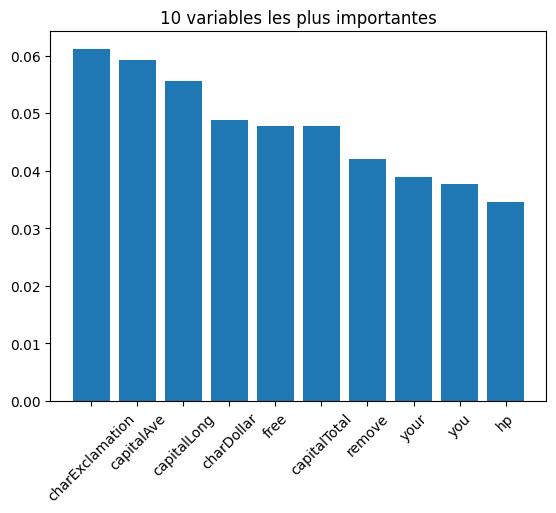

In [ ]:
meilleure_rf = grid.best_estimator_

importances = meilleure_rf.feature_importances_
'''
feature_importances_ renvoie un tableau contenant
un score pour chaque variable (57 au total). Plus la
valeur est élevée, plus la variable a permis de séparer
efficacement les spams des non-spams lors des
divisions de la forêt.
'''

indices = np.argsort(importances)[:: -1]
'''
np.argsort(importances) : Renvoie les indices
des variables triés de la plus petite à la plus
grande importance (ordre croissant).

[::-1] : Inverse le tableau NumPy pour obtenir
les indices triés du plus grand au plus petit
(ordre décroissant).

Exemple : Si la 5e variable est la plus
importante, le premier élément de indices
sera 4 (car l'indexation commence à 0).
'''

# Affichage des 10 premieres
plt.bar(range (10), importances[indices ][:10])
plt.xticks(range (10), X.columns[indices ][:10] , rotation =45)
plt.title("10 variables les plus importantes")
plt.show()

La variable la plus importante est "charExclamation"

En R, on utilise le package ranger pour avoir une implémentation plus rapide que randomForest.
En Python, comparer les temps de calcul de RandomForestClassifier avec 1 seul coeur (n_jobs=None)
et avec tous les coeurs disponibles (n_jobs=-1). Vous pouvez utiliser le module time de Python
pour mesurer la durée d’entraînement.

n_jobs=None (ou 1) : Le calcul est mono-cœur. Les arbres de la forêt sont construits les uns après les autres de manière séquentielle.

n_jobs=-1 : Scikit-Learn utilise tous les cœurs CPU disponibles sur la machine (par exemple les 2 cœurs alloués par défaut sur Google Colab). Les arbres sont construits en parallèle via le module joblib.

Mesure du temps : On utilise time.perf_counter() du module time, qui fournit un chronomètre haute précision adapté au benchmarking.

In [ ]:
import time

# 1. Entraînement avec 1 seul cœur CPU (séquentiel)
rf_single = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=1) #300 ESTIMTORS au lieu de 100 pour mieux voir la diff sur bcp de calculs

start_time = time.perf_counter()
rf_single.fit(X_train, y_train)
duration_single = time.perf_counter() - start_time

# 2. Entraînement avec TOUS les cœurs CPU (parallèle)
rf_multi = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)

start_time = time.perf_counter()
rf_multi.fit(X_train, y_train)
duration_multi = time.perf_counter() - start_time

# 3. Affichage des résultats et du facteur d'accélération (speedup)
speedup = duration_single / duration_multi

print("--- Comparaison des temps de calcul ---")
print(f"Temps avec 1 seul cœur (n_jobs=None) : {duration_single:.3f} secondes")
print(f"Temps avec tous les cœurs (n_jobs=-1) : {duration_multi:.3f} secondes")
print(f"Accélération (Speedup)               : x{speedup:.2f}")

--- Comparaison des temps de calcul ---
Temps avec 1 seul cœur (n_jobs=None) : 6.002 secondes
Temps avec tous les cœurs (n_jobs=-1) : 3.418 secondes
Accélération (Speedup)               : x1.76


Pour plusieurs calculs, avec plusieurs coeurs, c'est bien plus rapide puisque les calculs et les arbres sont fait en parallèles plutôt que chacun leurs tours avec 1 seul coeur

# **Exercice 2:**

On considère les données internet advertisements disponibles sur le dépôt.

1. Importer les données. Étant donné la nature de la base, vous devrez probablement forcer certains
types et traiter les données manquantes représentées par "?". Expliquer le problème (classification
de bannières publicitaires).

In [ ]:
# Chargement des donnees
ad = pd.read_csv("/content/drive/MyDrive/Machine Learning/Cours 3/spam.csv", sep=";", decimal=",")
print(spam.head())